<a href="https://colab.research.google.com/github/climatescience/Spatial-data-visualization-with-Python/blob/main/4_panel_spatial_map_with_shapefile.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

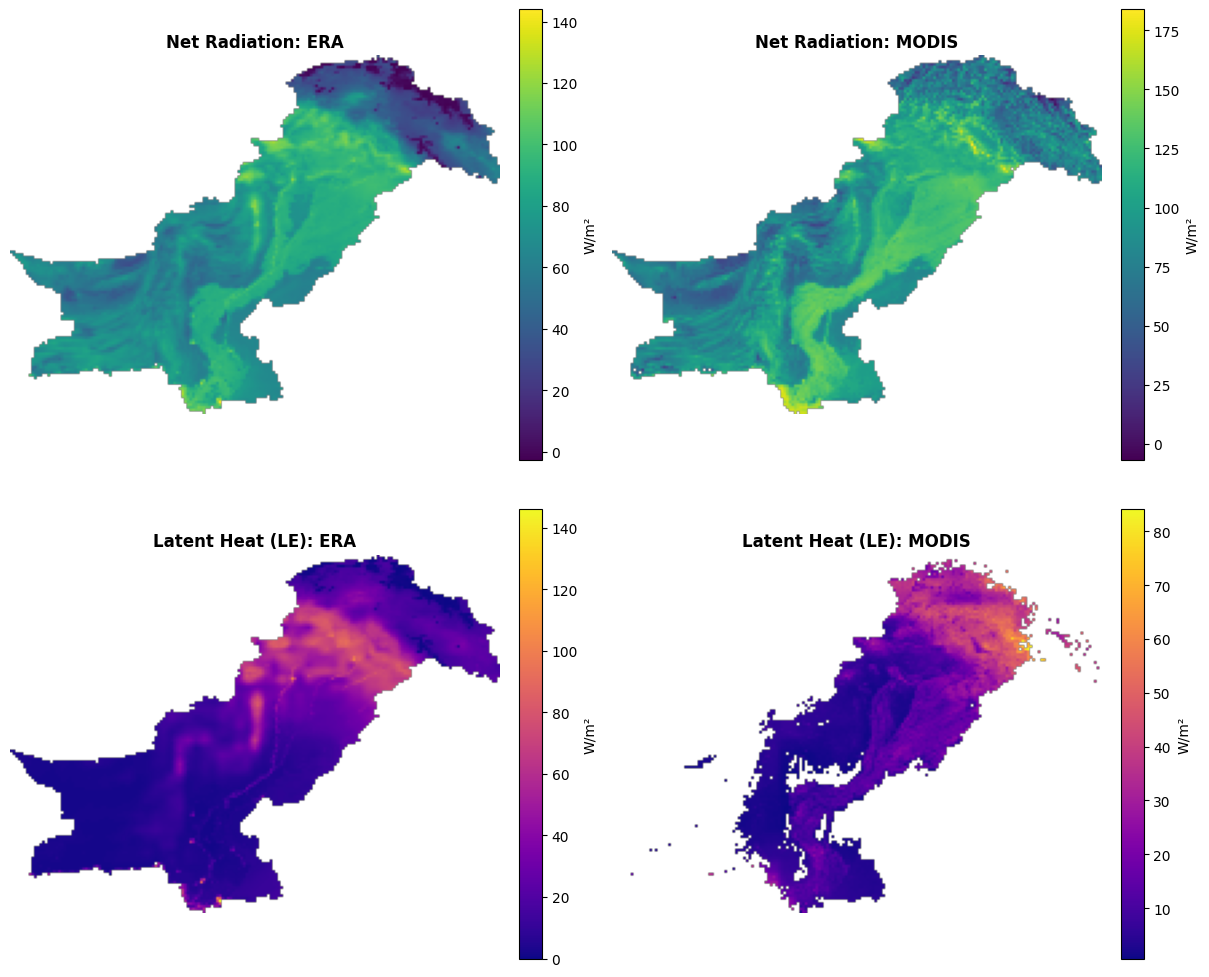

In [2]:
# 1. Install rasterio (Google Colab doesn't have it pre-installed)
!pip install rasterio -q

import rasterio
import matplotlib.pyplot as plt
import numpy as np
from google.colab import files



# --- CONFIGURE FILE NAMES ---
# Replace these strings with the exact filenames of your uploaded files
net_rad_era_path = 'ERA_RN.tif'     # Top-Left
net_rad_modis_path = 'MODIS_RN.tif' # Top-Right
le_era_path = 'ERA_LE.tif'               # Bottom-Left
le_modis_path = 'MODIS_LE.tif'           # Bottom-Right

# Helper function to read GeoTIFF and handle NoData values
def read_tif(path):
    with rasterio.open(path) as src:
        data = src.read(1)  # Read the first band
        nodata = src.nodata
        if nodata is not None:
            data = np.where(data == nodata, np.nan, data)
    return data

# Load the 4 datasets
nr_era = read_tif(net_rad_era_path)
nr_modis = read_tif(net_rad_modis_path)
le_era = read_tif(le_era_path)
le_modis = read_tif(le_modis_path)

# 3. Create the 4-Panel Plot
fig, axes = plt.subplots(2, 2, figsize=(12, 10), constrained_layout=True)

# --- TOP ROW: Net Radiation ---
# Top-Left: ERA Net Radiation
im1 = axes[0, 0].imshow(nr_era, cmap='viridis')
axes[0, 0].set_title('Net Radiation: ERA', fontsize=12, fontweight='bold')
axes[0, 0].axis('off')
fig.colorbar(im1, ax=axes[0, 0], orientation='vertical', fraction=0.046, pad=0.04, label='W/m²')

# Top-Right: MODIS Net Radiation
im2 = axes[0, 1].imshow(nr_modis, cmap='viridis')
axes[0, 1].set_title('Net Radiation: MODIS', fontsize=12, fontweight='bold')
axes[0, 1].axis('off')
fig.colorbar(im2, ax=axes[0, 1], orientation='vertical', fraction=0.046, pad=0.04, label='W/m²')


# --- BOTTOM ROW: Latent Heat (LE) ---
# Bottom-Left: ERA Latent Heat
im3 = axes[1, 0].imshow(le_era, cmap='plasma')
axes[1, 0].set_title('Latent Heat (LE): ERA', fontsize=12, fontweight='bold')
axes[1, 0].axis('off')
fig.colorbar(im3, ax=axes[1, 0], orientation='vertical', fraction=0.046, pad=0.04, label='W/m²')

# Bottom-Right: MODIS Latent Heat
im4 = axes[1, 1].imshow(le_modis, cmap='plasma')
axes[1, 1].set_title('Latent Heat (LE): MODIS', fontsize=12, fontweight='bold')
axes[1, 1].axis('off')
fig.colorbar(im4, ax=axes[1, 1], orientation='vertical', fraction=0.046, pad=0.04, label='W/m²')

# Show the final multi-panel map
plt.show()

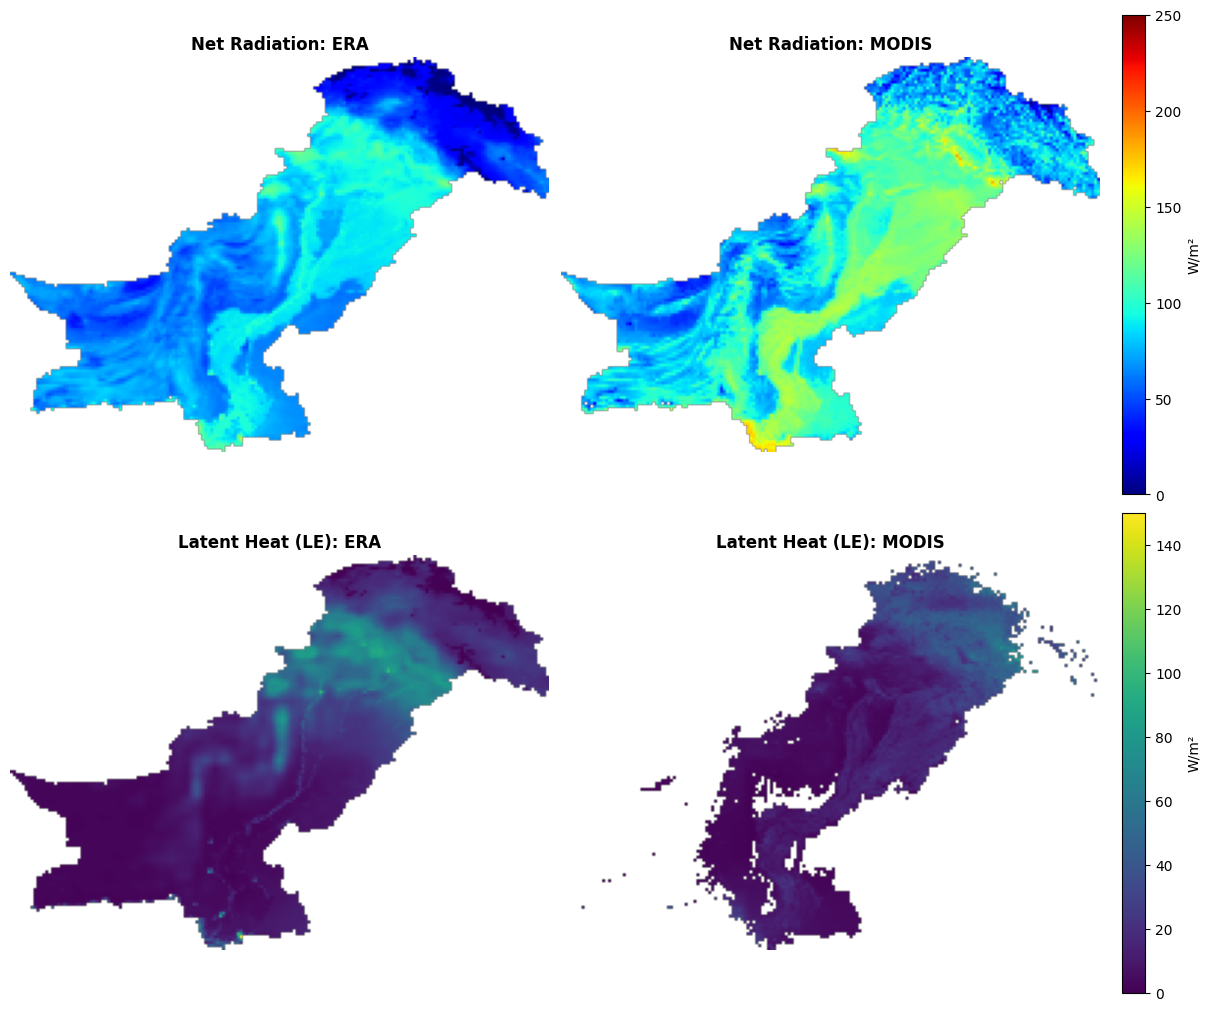

In [10]:
# 1. Install rasterio (Google Colab doesn't have it pre-installed)
!pip install rasterio -q

import rasterio
import matplotlib.pyplot as plt
import numpy as np

# --- CONFIGURE FILE NAMES ---
net_rad_era_path = 'ERA_RN.tif'     # Top-Left
net_rad_modis_path = 'MODIS_RN.tif' # Top-Right
le_era_path = 'ERA_LE.tif'               # Bottom-Left
le_modis_path = 'MODIS_LE.tif'           # Bottom-Right

# Helper function to read GeoTIFF and handle NoData values
def read_tif(path):
    with rasterio.open(path) as src:
        data = src.read(1)  # Read the first band
        nodata = src.nodata
        if nodata is not None:
            data = np.where(data == nodata, np.nan, data)
    return data

# Load the 4 datasets
nr_era = read_tif(net_rad_era_path)
nr_modis = read_tif(net_rad_modis_path)
le_era = read_tif(le_era_path)
le_modis = read_tif(le_modis_path)


# 2. Create the 4-Panel Plot with a fixed scale (0 to 250 W/m²)
fig, axes = plt.subplots(2, 2, figsize=(12, 10), constrained_layout=True)

# --- TOP ROW: Net Radiation ---
# Top-Left: ERA Net Radiation
im1 = axes[0, 0].imshow(nr_era, cmap='jet', vmin=0, vmax=250)
axes[0, 0].set_title('Net Radiation: ERA', fontsize=12, fontweight='bold')
axes[0, 0].axis('off')
#fig.colorbar(im1, ax=axes[0, 0], orientation='vertical', fraction=0.046, pad=0.04, label='W/m²')

# Top-Right: MODIS Net Radiation
im2 = axes[0, 1].imshow(nr_modis, cmap='jet', vmin=0, vmax=250)
axes[0, 1].set_title('Net Radiation: MODIS', fontsize=12, fontweight='bold')
axes[0, 1].axis('off')
fig.colorbar(im2, ax=axes[0, 1], orientation='vertical', fraction=0.046, pad=0.04, label='W/m²')


# --- BOTTOM ROW: Latent Heat (LE) ---
# Bottom-Left: ERA Latent Heat
im3 = axes[1, 0].imshow(le_era, cmap='jet', vmin=0, vmax=150)
axes[1, 0].set_title('Latent Heat (LE): ERA', fontsize=12, fontweight='bold')
axes[1, 0].axis('off')
#fig.colorbar(im3, ax=axes[1, 0], orientation='vertical', fraction=0.046, pad=0.04, label='W/m²')

# Bottom-Right: MODIS Latent Heat
im4 = axes[1, 1].imshow(le_modis, cmap='jet', vmin=0, vmax=150)
axes[1, 1].set_title('Latent Heat (LE): MODIS', fontsize=12, fontweight='bold')
axes[1, 1].axis('off')
fig.colorbar(im4, ax=axes[1, 1], orientation='vertical', fraction=0.046, pad=0.04, label='W/m²')

# Show the final multi-panel map
plt.show()

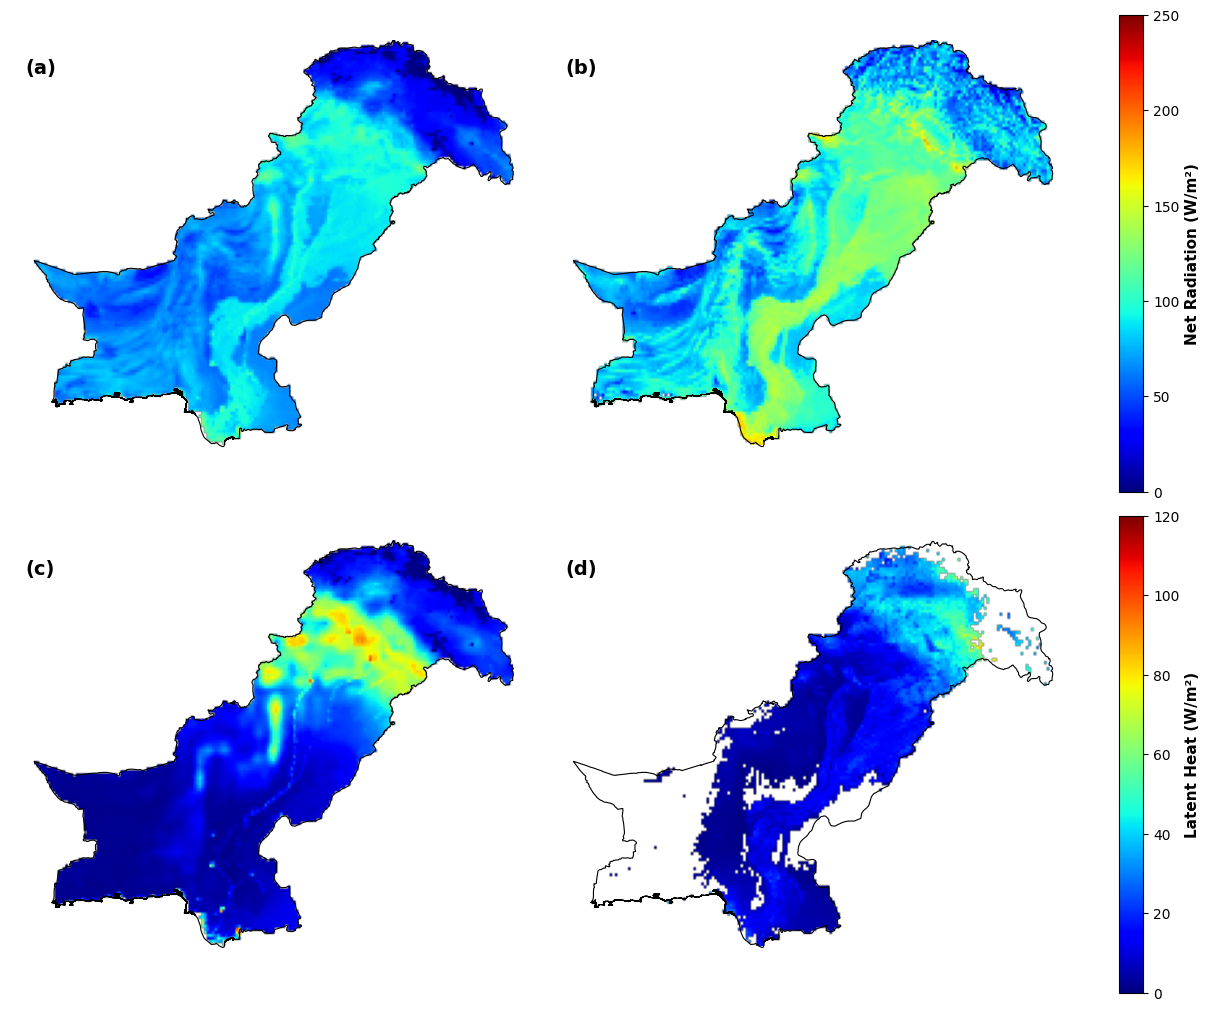

In [27]:
# 1. Install required libraries (rasterio and geopandas)
!pip install rasterio geopandas -q

import rasterio
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np

# --- CONFIGURE FILE NAMES ---
net_rad_era_path = 'ERA_RN.tif'     # Top-Left
net_rad_modis_path = 'MODIS_RN.tif' # Top-Right
le_era_path = 'ERA_LE.tif'               # Bottom-Left
le_modis_path = 'MODIS_LE.tif'           # Bottom-Right

shapefile_path = 'PAK_adm0.shp'

# Helper function to read GeoTIFF, handle NoData, and get spatial extent
def read_tif(path):
    with rasterio.open(path) as src:
        data = src.read(1)
        nodata = src.nodata
        if nodata is not None:
            data = np.where(data == nodata, np.nan, data)
        bounds = src.bounds
        extent = [bounds.left, bounds.right, bounds.bottom, bounds.top]
    return data, extent

# Load the 4 datasets and their respective extents
nr_era, ext_nr_era = read_tif(net_rad_era_path)
nr_modis, ext_nr_mod = read_tif(net_rad_modis_path)
le_era, ext_le_era = read_tif(le_era_path)
le_modis, ext_le_mod = read_tif(le_modis_path)

# Load boundary shapefile and reproject to match raster CRS
with rasterio.open(net_rad_era_path) as src:
    raster_crs = src.crs

boundary_gdf = gpd.read_file(shapefile_path).to_crs(raster_crs)

# 2. Create the 4-Panel Plot
fig, axes = plt.subplots(2, 2, figsize=(12, 10), constrained_layout=True)

# --- TOP ROW: Net Radiation (Scale: 0 to 250) ---
im1 = axes[0, 0].imshow(nr_era, cmap='jet', vmin=0, vmax=250, extent=ext_nr_era)
axes[0, 0].text(0.03, 0.92, '(a)', transform=axes[0, 0].transAxes, fontsize=14, fontweight='bold', color='black', bbox=dict(facecolor='white', alpha=0.7, edgecolor='none', pad=2))
axes[0, 0].axis('off')

im2 = axes[0, 1].imshow(nr_modis, cmap='jet', vmin=0, vmax=250, extent=ext_nr_mod)
axes[0, 1].text(0.03, 0.92, '(b)', transform=axes[0, 1].transAxes, fontsize=14, fontweight='bold', color='black', bbox=dict(facecolor='white', alpha=0.7, edgecolor='none', pad=2))
axes[0, 1].axis('off')

cbar1 = fig.colorbar(im2, ax=axes[0, :], orientation='vertical', fraction=0.03, pad=0.04)
cbar1.set_label('Net Radiation (W/m²)', fontsize=11, fontweight='bold')

# --- BOTTOM ROW: Latent Heat (LE) (Scale: 0 to 200) ---
im3 = axes[1, 0].imshow(le_era, cmap='jet', vmin=0, vmax=120, extent=ext_le_era)
axes[1, 0].text(0.03, 0.92, '(c)', transform=axes[1, 0].transAxes, fontsize=14, fontweight='bold', color='black', bbox=dict(facecolor='white', alpha=0.7, edgecolor='none', pad=2))
axes[1, 0].axis('off')

im4 = axes[1, 1].imshow(le_modis, cmap='jet', vmin=0, vmax=120, extent=ext_le_mod)
axes[1, 1].text(0.03, 0.92, '(d)', transform=axes[1, 1].transAxes, fontsize=14, fontweight='bold', color='black', bbox=dict(facecolor='white', alpha=0.7, edgecolor='none', pad=2))
axes[1, 1].axis('off')

cbar2 = fig.colorbar(im4, ax=axes[1, :], orientation='vertical', fraction=0.03, pad=0.04)
cbar2.set_label('Latent Heat (W/m²)', fontsize=11, fontweight='bold')

# --- ADD SHAPEFILE BOUNDARY TO ALL PANELS ---
for ax in axes.flat:
    boundary_gdf.boundary.plot(ax=ax, color='black', linewidth=0.8)

plt.show()